# Multi-Fidelity Method Comparison: Meng Discontinuous Case

Example is based on the composite NN test case that presents a 1D test case with a discontinuity in the center

In [1]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import torch
import numpy as np

from SurrogateModels import mfsnn, cokriging, mfkans
import multi_fidelity_functions

Introduce the example function

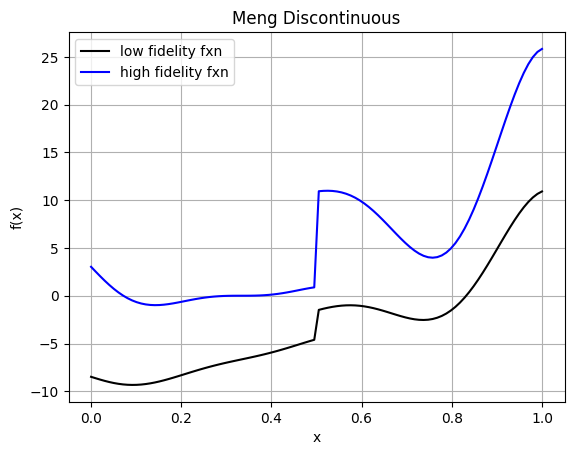

In [2]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.MengDiscontinuous()
mf_example.plot_functions(name=mf_example.name)
plt.legend()
plt.grid()
plt.show()

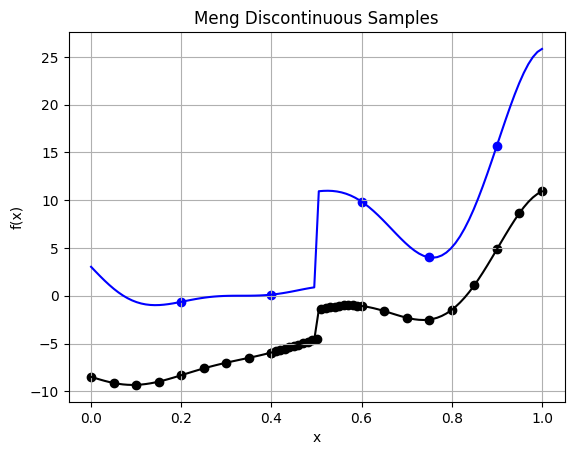

In [8]:
# Define the example function bounds and dimensions here
dim = mf_example.dimensions
xmin = mf_example.bounds[0][0]
xmax = mf_example.bounds[0][1]

n_lf = 11  # number of low fidelity points
n_hf = 6  # number of high fidelity points
n_test = 40  # number of test points

# Generate the analytical functions
hf_fxn = mf_example.high_fidelity
lf_fxn = mf_example.low_fidelity

lf_samp = 38
X_lf = np.zeros([lf_samp,1], dtype=np.float32)
X_lf[0:9,0] = np.linspace(0.0,0.4,9,endpoint=True)
X_lf[9:29,0] = np.linspace(0.4,0.6,20,endpoint=False)
X_lf[29:,0] = np.linspace(0.6,1.0,9,endpoint=True)
y_lf = lf_fxn(X_lf)

hf_samp = 5
X_hf = np.zeros([hf_samp,1], dtype=np.float32)
X_hf[:,0] = np.array([0.2,0.4,0.6,0.75,0.9])
y_hf = hf_fxn(X_hf)


X_test = np.linspace(xmin, xmax, n_test, dtype=np.float32).reshape(-1, 1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = mf_example.name + " Samples"

mf_example.plot_functions(name=plot_name)

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color="blue", label="HF samples", marker="o")
plt.scatter(X_lf, y_lf, color="black", label="LF samples", marker="o")

plt.grid()
plt.show()

## Multi-Fidelity Neural Network Fit

Using the method outlined by Meng and Karniadakis in the 2020 paper 
"A composite neural network that learns from multi-fidelity data: Application to function approximation and inverse PDE problems"
 generate a multi-fidelity function fit using the data defined from the analytical functions.

In [11]:
mfnn_model = mfsnn.MultiFidelityNN(
    X_lf=X_lf,
    y_lf=y_lf,
    X_lf_test=X_test,
    y_lf_test=y_lf_test,
    X_hf=X_hf,
    y_hf=y_hf,
    X_hf_test=X_test,
    y_hf_test=y_hf_test,
    lf_nn_dim=[20, 20, 20],
    hf_nl_nn_dim=[10, 10],
    epochs_lf=100,
    epochs_mf=1000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf=0.01,
    wd_mf=0.01,
)

Epoch: 0   || Train Error: 0.5887576341629028 || Test Error: 0.7981964349746704

Epoch: 1   || Train Error: 0.5057314038276672 || Test Error: 0.7059933543205261

Epoch: 2   || Train Error: 0.24208249151706696 || Test Error: 0.3268662989139557

Epoch: 3   || Train Error: 0.1512300670146942 || Test Error: 0.1923227608203888

Epoch: 4   || Train Error: 0.12435053288936615 || Test Error: 0.15601924061775208

Epoch: 5   || Train Error: 0.11143376678228378 || Test Error: 0.13948960602283478

Epoch: 6   || Train Error: 0.10280826687812805 || Test Error: 0.12910196185112

Epoch: 7   || Train Error: 0.09730874001979828 || Test Error: 0.12294652312994003

Epoch: 8   || Train Error: 0.09376515448093414 || Test Error: 0.11927922070026398

Epoch: 9   || Train Error: 0.09111841768026352 || Test Error: 0.11662594974040985

Epoch: 10   || Train Error: 0.08792814612388611 || Test Error: 0.113527812063694

Epoch: 11   || Train Error: 0.08626313507556915 || Test Error: 0.11217057704925537

Epoch: 12   ||

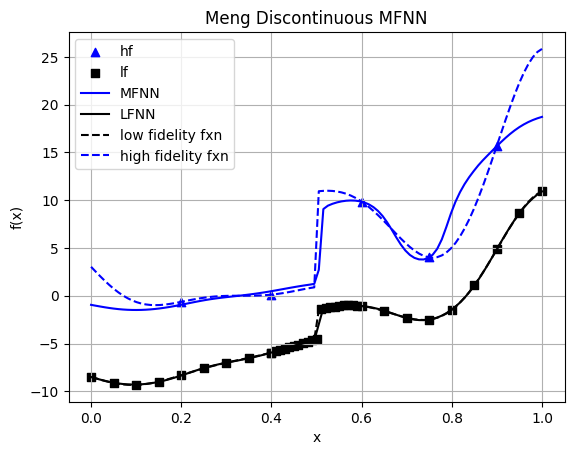

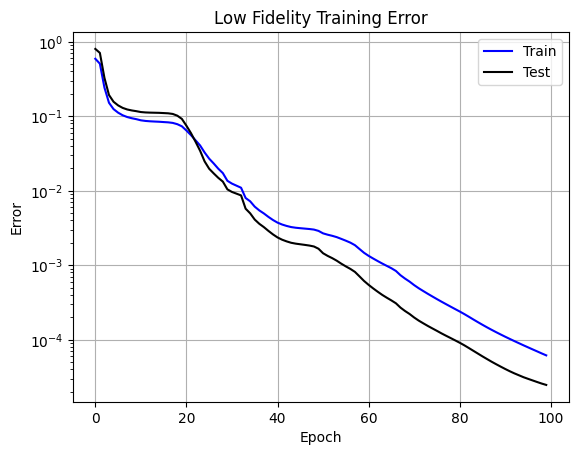

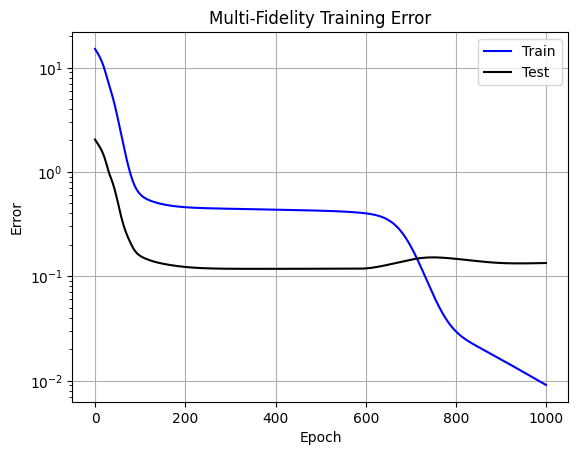

In [12]:
# Plot the results
plot_name = mf_example.name + " MFNN"

ax = mfnn_model.plot_data(plot_name)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MFNN",
    linestyle="solid",
    ax=ax,
)
ax = mfnn_model.low_fidelity_nn.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="black",
    label="LFNN",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Plot the model error
mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()
mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()

## Co-Kriging Function Fit

Utilizes the Co-Kriging function fit outlined in the Forrester 2007 paper.

In [15]:
cokriging_model = cokriging.CoKriging(X_lf, y_lf, X_hf, y_hf)

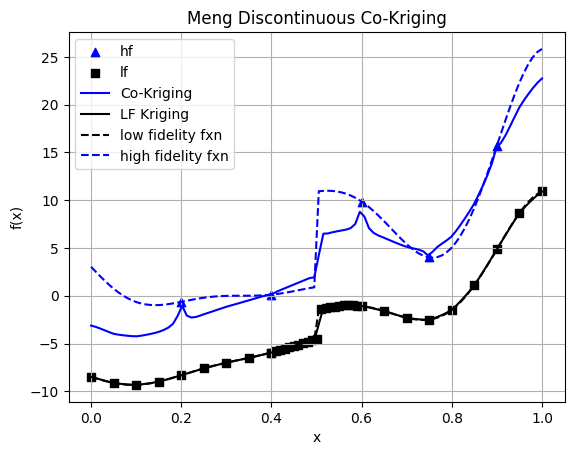

In [16]:
# Plot the results
plot_name = mf_example.name + " Co-Kriging"

ax = cokriging_model.plot_data(plot_name)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="Co-Kriging",
    linestyle="solid",
    ax=ax,
)
ax = cokriging_model.kriging_lf.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF Kriging",
    color="black",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

### MFKAN Model
Sets up a MFKAN model for a 1D dataset

In [ ]:
# MFKAN Model for forrester mf example
mfkan_model = mfkans.MFKANModel(
    x_lf=X_lf,
    y_lf=y_lf,
    x_lf_test=X_test,
    y_lf_test=y_lf_test,
    x_hf=X_hf,
    y_hf=y_hf,
    x_hf_test=X_test,
    y_hf_test=y_hf_test,
    spline_order_lf=3,
    spline_order_mf=3,
    width_lf=[1, 1],
    width_mf=[2, 1, 1],
    grid_lf=3,
    grid_mf=3,
    opt_lf="LBFGS",
    opt_mf="LBFGS",
    n_iter_lf=100,
    n_iter_mf=100,
)

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 3.25e-01 | test_loss: 2.26e-01 | reg: 1.38e+01 | : 100%|█| 100/100 [00:02<00:00, 35.47


saving model version 0.1
saving model version 0.2


| train_loss: 3.25e-01 | test_loss: 2.26e-01 | reg: 1.38e+01 | : 100%|█| 100/100 [00:02<00:00, 47.42


saving model version 0.3
saving model version 0.4


| train_loss: 3.25e-01 | test_loss: 2.26e-01 | reg: 1.38e+01 | : 100%|█| 100/100 [00:02<00:00, 46.69


... (23 outputs left out)

| train_loss: 7.76e-07 | test_loss: 4.21e+00 | reg: 1.84e+01 | : 100%|█| 100/100 [00:03<00:00, 27.32


saving model version 0.13
saving model version 0.14


| train_loss: 1.04e-06 | test_loss: 4.21e+00 | reg: 1.84e+01 | : 100%|█| 100/100 [00:03<00:00, 30.19


saving model version 0.15


C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\mf_model.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


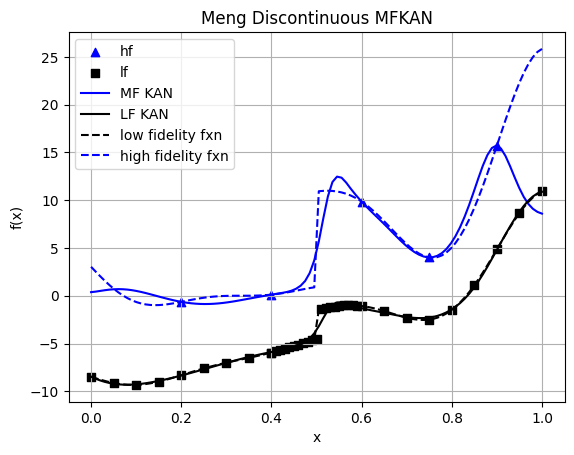

In [23]:
# Plot the results
plot_name = mf_example.name + " MFKAN"

ax = mfkan_model.plot_data(plot_name)
ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="solid",
    ax=ax,
)
ax = mfkan_model.lf_kan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF KAN",
    color="black",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Model Comparison

Compare the three different methods for their ability to fit the high fidelity function.

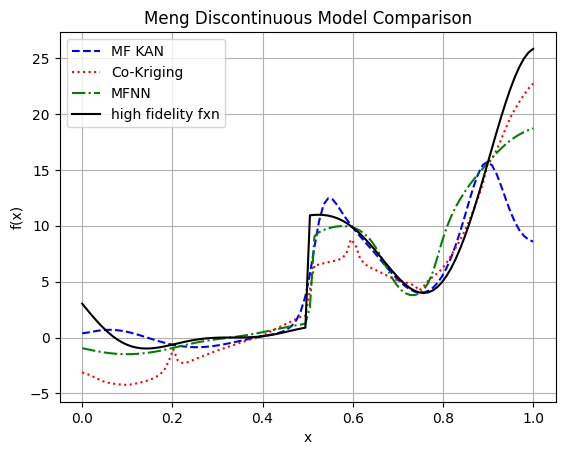

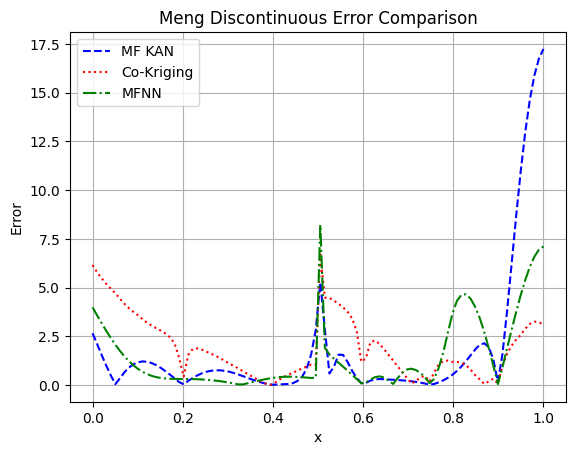

In [21]:
plot_name = mf_example.name + " Model Comparison"

ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
ax = mf_example.plot_high_fidelity(
    name=plot_name, linestyle="solid", color="black", ax=ax
)
plt.legend()
plt.grid()
plt.show()

plot_name = mf_example.name + " Error Comparison"

ax = mfkan_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
)
ax = cokriging_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
plt.legend()
plt.grid()
plt.show()